# PRCP-1015: Richter's Predictor – Modeling Earthquake Damage

**Goal:** Predict the ordinal target `damage_grade` (1 = low damage, 2 = medium damage, 3 = near-complete destruction) for buildings hit by the 2015 Gorkha earthquake in Nepal, using building structure, location and ownership features.

**Contents**
1. Task 1 – Data analysis report (EDA)
2. Task 2 – Predictive model for `damage_grade`
3. Task 3 – Suggestions to seismologists
4. Model comparison report
5. Report on challenges faced

**Files expected in the same folder:** `train_values.csv`, `train_labels.csv`

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, recall_score)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
pd.set_option('display.max_columns', 60)

# Task 1 – Data Analysis Report

## 1.1 Load and merge the data

In [4]:
values = pd.read_csv(r'C:\Users\aakas\Downloads\PRCP-1015-EquakeDamagePred\Data\train_values.csv')
labels = pd.read_csv(r'C:\Users\aakas\Downloads\PRCP-1015-EquakeDamagePred\Data\train_labels.csv')
df = values.merge(labels, on='building_id', how='inner')
print('values:', values.shape, '| labels:', labels.shape, '| merged:', df.shape)
df.head()

values: (260601, 39) | labels: (260601, 2) | merged: (260601, 40)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3


## 1.2 Structure, data types, missing values and duplicates

In [5]:
print(df.dtypes.value_counts(), '\n')
print('Total missing values :', int(df.isna().sum().sum()))
print('Duplicate building_id:', int(df.duplicated('building_id').sum()))
print('Fully duplicated rows (ignoring id):', int(df.drop(columns='building_id').duplicated().sum()))

cat_cols = df.select_dtypes(include='object').columns.tolist()
geo_cols = ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']
num_cols = ['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families']
bin_cols = [c for c in df.columns if c.startswith('has_')]
sup_cols = [c for c in bin_cols if c.startswith('has_superstructure')]
sec_cols = [c for c in bin_cols if c.startswith('has_secondary_use')]
print('\ncategorical:', cat_cols)
print('numeric    :', num_cols)
print('binary flags:', len(bin_cols), '(superstructure:', len(sup_cols), ', secondary use:', len(sec_cols), ')')

int64    32
str       8
Name: count, dtype: int64 

Total missing values : 0
Duplicate building_id: 0
Fully duplicated rows (ignoring id): 12319

categorical: ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']
numeric    : ['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families']
binary flags: 22 (superstructure: 11 , secondary use: 11 )


**Observations**
- 260,601 buildings and 40 columns (id + 38 features + target). All 38 features plus the target are present for every row, so **there are no missing values** and no duplicate building ids.
- Features are a mix of 8 obfuscated categorical columns, 3 geographic ids, 5 numeric columns and 22 binary flags.

## 1.3 Target variable – `damage_grade`

               count  share_%
damage_grade                 
1              25124     9.64
2             148259    56.89
3              87218    33.47


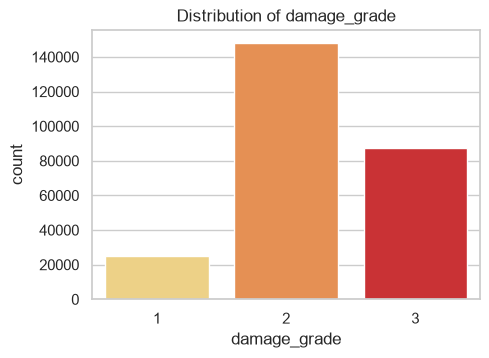

In [6]:
vc = df['damage_grade'].value_counts().sort_index()
print(pd.DataFrame({'count': vc, 'share_%': (vc / len(df) * 100).round(2)}))
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x='damage_grade', data=df, ax=ax, palette='YlOrRd')
ax.set_title('Distribution of damage_grade')
plt.show()

**Observations:** The classes are **imbalanced**. Grade 2 (medium damage) is the majority at about 57%, grade 3 is about 33%, and grade 1 (low damage) is only about 10%. Plain accuracy would therefore be misleading for grade 1, so macro-F1 and per-class recall are tracked alongside the competition metric (micro-averaged F1).

## 1.4 Numeric features

,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,260601.0,2.129723,0.727665,1.0,2.0,2.0,2.0,9.0
age,260601.0,26.535029,73.565937,0.0,10.0,15.0,30.0,995.0
area_percentage,260601.0,8.018051,4.392231,1.0,5.0,7.0,9.0,100.0
height_percentage,260601.0,5.434365,1.918418,2.0,4.0,5.0,6.0,32.0
count_families,260601.0,0.983949,0.418389,0.0,1.0,1.0,1.0,9.0


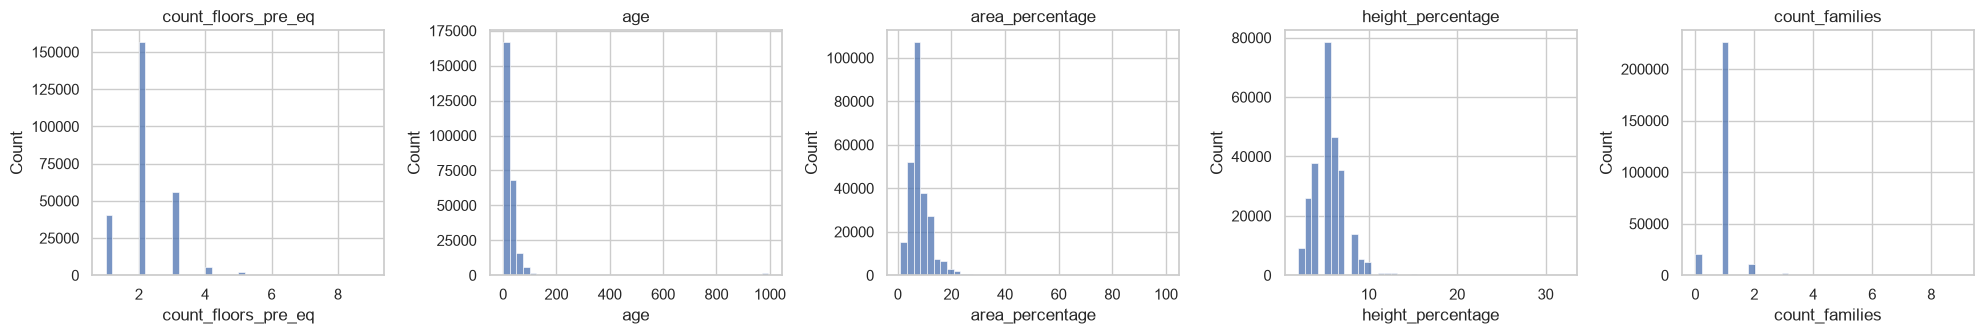

Rows with age >= 200: 1496
age
995    1390
100    1364
120     180
150     142
200     106
110     100
105      89
125      37
Name: count, dtype: int64


In [7]:
display(df[num_cols].describe().T)
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c], bins=40, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

print('Rows with age >= 200:', (df.age >= 200).sum())
print(df.loc[df.age >= 100, 'age'].value_counts().head(8))

**Observations**
- `age` has a median of 15 years but a maximum of 995. About 1,500 buildings have an age of 200 or more, and these appear to be placeholder or data-entry values rather than real ages. They are capped and flagged during preprocessing.
- `area_percentage` (max 100) and `height_percentage` (max 32) are right-skewed with a few large values. Most buildings have 2 floors and a single family.

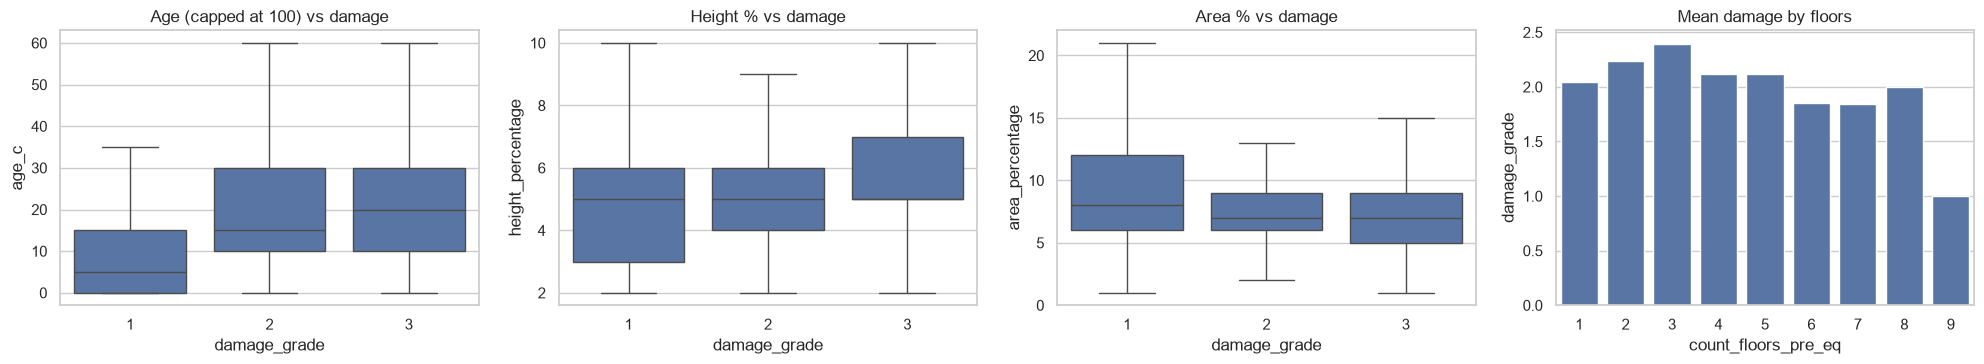

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
df['age_c'] = df['age'].clip(upper=100)
sns.boxplot(x='damage_grade', y='age_c', data=df, ax=axes[0], showfliers=False); axes[0].set_title('Age (capped at 100) vs damage')
sns.boxplot(x='damage_grade', y='height_percentage', data=df, ax=axes[1], showfliers=False); axes[1].set_title('Height % vs damage')
sns.boxplot(x='damage_grade', y='area_percentage', data=df, ax=axes[2], showfliers=False); axes[2].set_title('Area % vs damage')
sns.barplot(x='count_floors_pre_eq', y='damage_grade', data=df, ax=axes[3], errorbar=None); axes[3].set_title('Mean damage by floors')
plt.tight_layout(); plt.show()
df.drop(columns='age_c', inplace=True)

**Observations:** Older buildings and buildings with more floors tend toward higher damage grades, while larger footprints (`area_percentage`) tend toward lower damage. The effects are moderate, so these variables help but do not separate the classes on their own.

## 1.5 Categorical features vs damage

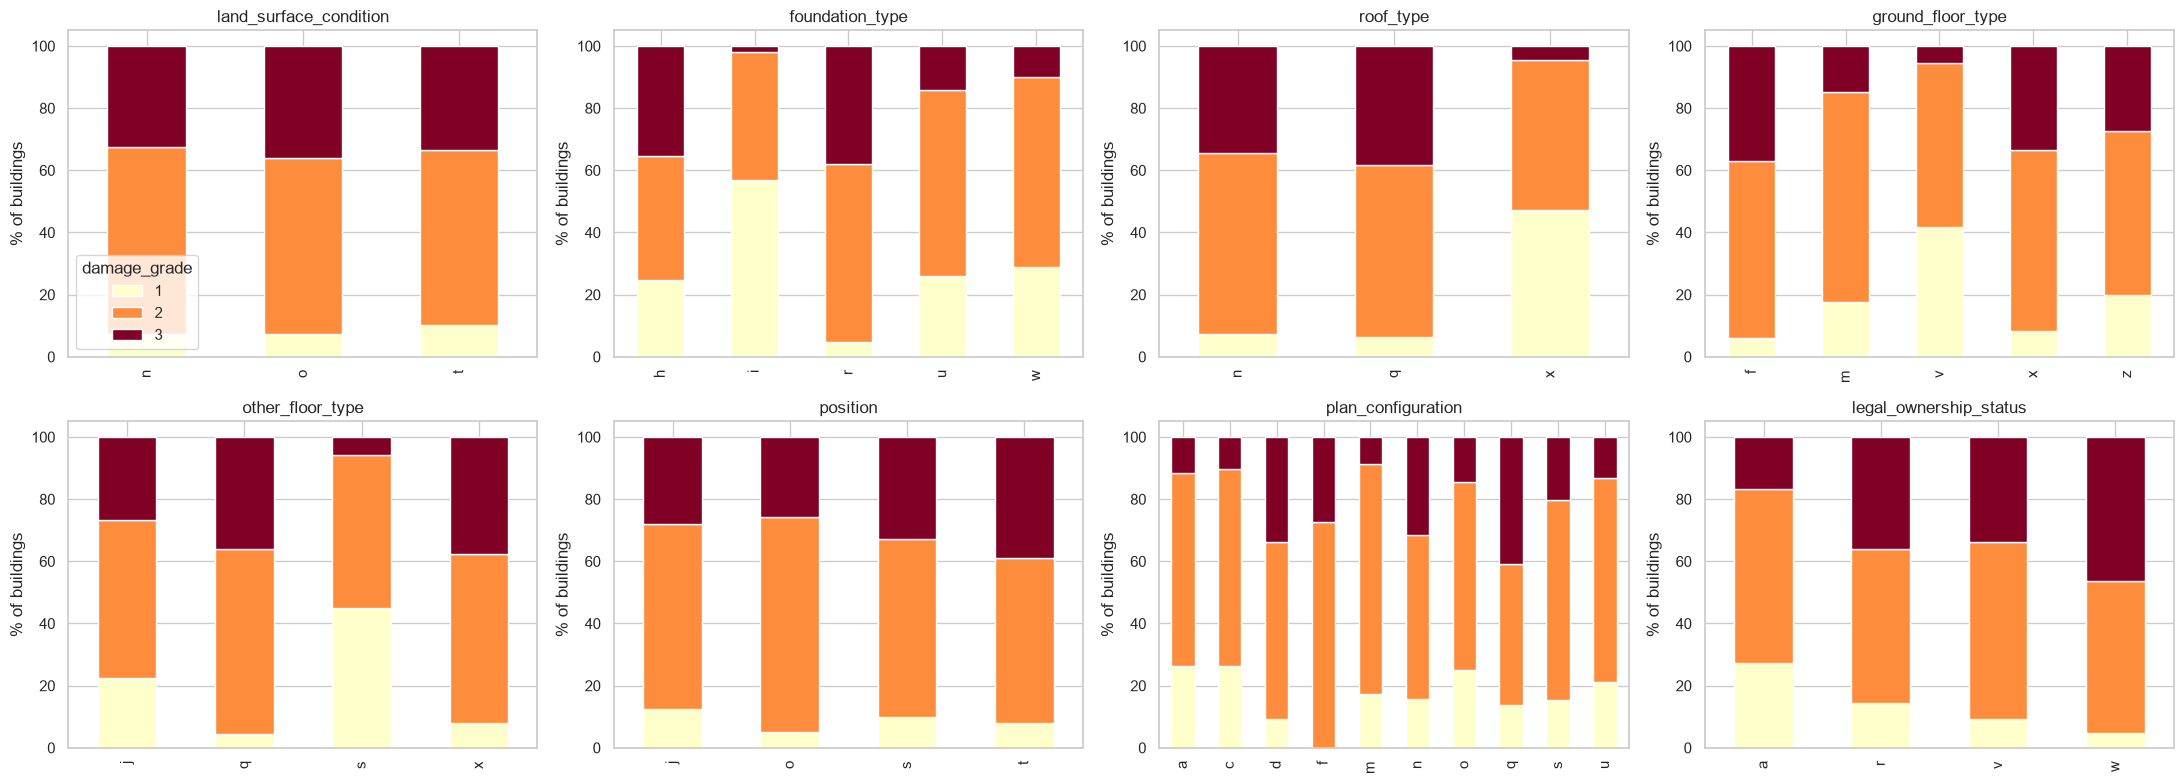

damage_grade        1     2     3       n
foundation_type                          
h                0.25  0.40  0.35    1448
i                0.57  0.41  0.02   10579
r                0.05  0.57  0.38  219196
u                0.26  0.60  0.14   14260
w                0.29  0.61  0.10   15118 

damage_grade     1     2     3       n
roof_type                             
n             0.07  0.58  0.34  182842
q             0.06  0.55  0.38   61576
x             0.47  0.48  0.05   16183 

damage_grade          1     2     3       n
ground_floor_type                          
f                  0.06  0.57  0.37  209619
m                  0.18  0.68  0.15     508
v                  0.42  0.53  0.05   24593
x                  0.08  0.58  0.33   24877
z                  0.20  0.53  0.27    1004 

damage_grade         1     2     3       n
other_floor_type                          
j                 0.22  0.51  0.27   39843
q                 0.04  0.59  0.36  165282
s                 0.45  0

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(22, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    ct = pd.crosstab(df[c], df['damage_grade'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, ax=ax, colormap='YlOrRd', legend=False)
    ax.set_title(c); ax.set_ylabel('% of buildings'); ax.set_xlabel('')
axes[0, 0].legend(title='damage_grade', loc='lower left')
plt.tight_layout(); plt.show()

for c in ['foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type']:
    print(pd.crosstab(df[c], df['damage_grade'], normalize='index').round(2).assign(n=df[c].value_counts()), '\n')

**Observations**
- **Foundation type:** type `r` (84% of buildings) has about 38% grade-3 damage, whereas type `i` has only about 2% grade-3 and over half of its buildings are grade 1.
- **Roof type:** roof `x` buildings are much less damaged (about 47% grade 1) than `n` and `q` roofs.
- **Ground and other floor types:** ground floor `v` and other-floor `s` are associated with markedly lower damage than the dominant `f` and `q` types.
- **Plan configuration and ownership:** plan `q` and ownership status `w` and `r` show higher grade-3 shares, but each covers a small number of buildings.
- Because the letters are obfuscated, these results show *which category codes* are risky, not what the real-world construction types are.

## 1.6 Superstructure materials and secondary use

,material,share_%,mean_damage_if_1,mean_damage_if_0,pct_grade3_if_1
2,stone_flag,3.4,2.45,2.23,47.3
0,adobe_mud,8.9,2.35,2.23,37.2
1,mud_mortar_stone,76.2,2.34,1.92,38.2
4,mud_mortar_brick,6.8,2.27,2.24,30.6
6,timber,25.5,2.17,2.26,28.0
7,bamboo,8.5,2.11,2.25,24.0
10,other,1.5,2.09,2.24,25.6
3,cement_mortar_stone,1.8,1.97,2.24,14.2
8,rc_non_engineered,4.3,1.78,2.26,12.7
5,cement_mortar_brick,7.5,1.69,2.28,5.6


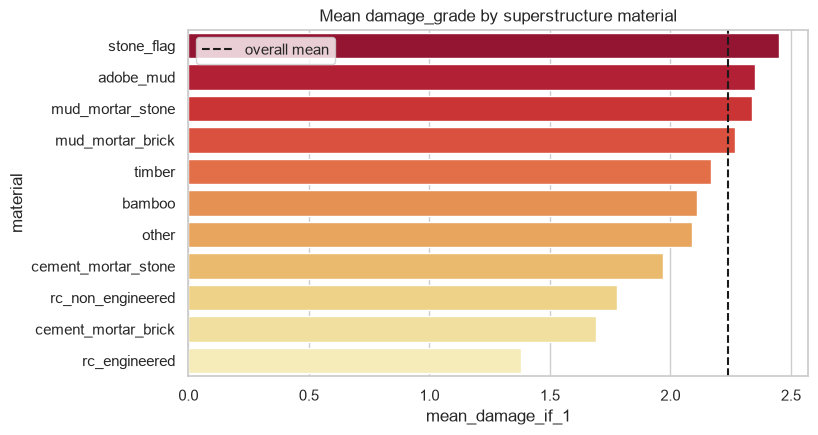

,share_%,mean_damage_if_1
has_secondary_use,11.19,2.10
has_secondary_use_agriculture,6.44,2.26
has_secondary_use_hotel,3.36,1.92
has_secondary_use_rental,0.81,1.67
has_secondary_use_institution,0.09,1.67
has_secondary_use_school,0.04,1.86
has_secondary_use_industry,0.11,2.03
has_secondary_use_health_post,0.02,1.86
has_secondary_use_gov_office,0.01,1.76
has_secondary_use_use_police,0.01,2.13


In [10]:
rows = []
for c in sup_cols:
    rows.append({'material': c.replace('has_superstructure_', ''),
                 'share_%': round(df[c].mean() * 100, 1),
                 'mean_damage_if_1': round(df.loc[df[c] == 1, 'damage_grade'].mean(), 2),
                 'mean_damage_if_0': round(df.loc[df[c] == 0, 'damage_grade'].mean(), 2),
                 'pct_grade3_if_1': round((df.loc[df[c] == 1, 'damage_grade'] == 3).mean() * 100, 1)})
mat = pd.DataFrame(rows).sort_values('mean_damage_if_1', ascending=False)
display(mat)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(y='material', x='mean_damage_if_1', data=mat, ax=ax, palette='YlOrRd_r')
ax.axvline(df['damage_grade'].mean(), color='k', ls='--', label='overall mean')
ax.set_title('Mean damage_grade by superstructure material'); ax.legend()
plt.show()

sec = pd.DataFrame({'share_%': (df[sec_cols].mean() * 100).round(2),
                    'mean_damage_if_1': [df.loc[df[c] == 1, 'damage_grade'].mean().round(2) for c in sec_cols]})
display(sec)

**Observations**
- **Highest-risk materials:** stone (mean 2.45), mud-mortar-stone (2.34, used in about 76% of buildings) and adobe/mud (2.35).
- **Lowest-risk materials:** engineered reinforced concrete (mean 1.38), cement-mortar-brick (1.69) and non-engineered RC (1.78). Cement-mortar-stone is also better than average (1.97).
- Mud-mortar-stone dominance in the building stock explains much of the overall damage. Cement or concrete binders versus mud binders is the most visible separating factor in the data.
- Secondary-use flags are rare (most buildings are purely residential), so they carry little signal individually.

## 1.7 Geography

geo_level_1_id,26,24,5,20,13,1,22,30,9,14,25,19,0,29,15,12,6,4,2,16,23,7,3,10,11,28,27,8,21,18,17
mean_damage,1.73,1.89,1.92,1.93,1.94,1.96,2.00,2.02,2.03,2.05,2.05,2.06,2.07,2.08,2.14,2.15,2.16,2.16,2.16,2.17,2.19,2.30,2.33,2.34,2.34,2.41,2.45,2.49,2.56,2.71,2.79
buildings,22615.00,1310.00,2690.00,17216.00,9608.00,2701.00,6252.00,2686.00,3958.00,1714.00,5624.00,372.00,4011.00,396.00,2320.00,3194.00,24381.00,14568.00,931.00,4332.00,1121.00,18994.00,7540.00,22079.00,8220.00,265.00,12532.00,19080.00,14889.00,3189.00,21813.00
pct_grade3,8.59,10.08,8.55,11.88,14.23,11.29,13.07,11.43,16.78,16.10,13.73,17.74,14.93,9.85,20.86,21.45,24.82,19.79,25.35,21.79,25.07,35.21,36.41,39.68,38.47,40.75,48.36,51.95,58.50,73.10,80.75


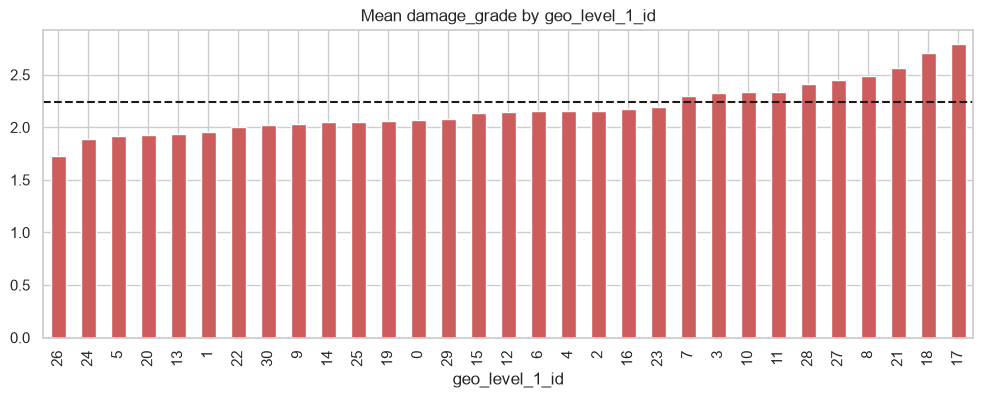

Unique geo_level_2_id: 1414 | unique geo_level_3_id: 11595


In [11]:
g1 = df.groupby('geo_level_1_id')['damage_grade'].agg(mean_damage='mean', buildings='size',
                                                       pct_grade3=lambda s: (s == 3).mean() * 100).round(2)
display(g1.sort_values('mean_damage').T)
fig, ax = plt.subplots(figsize=(12, 4))
g1.sort_values('mean_damage')['mean_damage'].plot(kind='bar', ax=ax, color='indianred')
ax.axhline(df['damage_grade'].mean(), color='k', ls='--')
ax.set_title('Mean damage_grade by geo_level_1_id'); plt.show()
print('Unique geo_level_2_id:', df.geo_level_2_id.nunique(), '| unique geo_level_3_id:', df.geo_level_3_id.nunique())

**Observations:** Location matters a lot. Mean damage ranges from about 1.73 (region 26) to about 2.79 (region 17) across the 31 level-1 regions. `geo_level_2_id` has 1,414 and `geo_level_3_id` has 11,595 distinct values, so the finer levels are high-cardinality and need careful handling.

## 1.8 Correlations

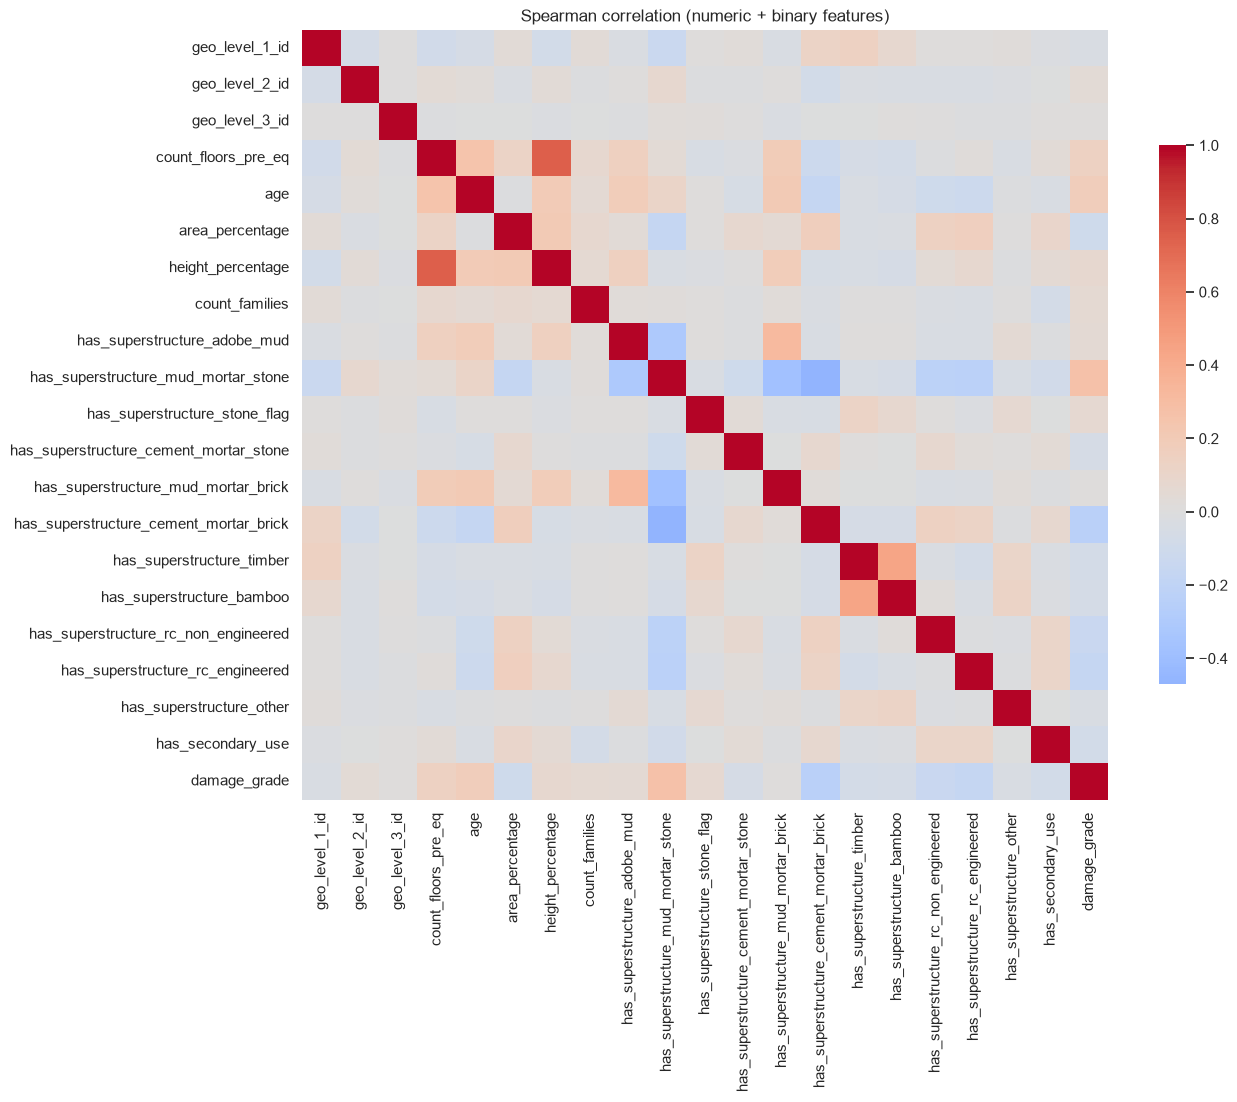

has_superstructure_cement_mortar_brick   -0.240
has_superstructure_rc_engineered         -0.162
has_superstructure_rc_non_engineered     -0.147
area_percentage                          -0.100
has_secondary_use                        -0.078
has_superstructure_timber                -0.071
has_superstructure_bamboo                -0.064
has_superstructure_cement_mortar_stone   -0.060
geo_level_1_id                           -0.035
has_superstructure_other                 -0.029
has_superstructure_mud_mortar_brick       0.008
geo_level_3_id                            0.009
geo_level_2_id                            0.042
has_superstructure_adobe_mud              0.050
count_families                            0.061
has_superstructure_stone_flag             0.065
height_percentage                         0.080
count_floors_pre_eq                       0.142
age                                       0.173
has_superstructure_mud_mortar_stone       0.273
Name: damage_grade, dtype: float64


In [12]:
corr_cols = geo_cols + num_cols + sup_cols + ['has_secondary_use', 'damage_grade']
corr = df[corr_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, ax=ax, cbar_kws={'shrink': .7})
ax.set_title('Spearman correlation (numeric + binary features)'); plt.show()
print(corr['damage_grade'].drop('damage_grade').sort_values().round(3))

**Observations:** No single feature has a strong linear or rank correlation with `damage_grade` (the largest values are around ±0.3, e.g. mud-mortar-stone positively, cement-mortar-brick and RC negatively). The signal is spread across many features and their interactions, which points toward tree-based ensemble models.

# Task 2 – Predictive Model for `damage_grade`

**Evaluation metric:** micro-averaged F1, which is the metric used by the DrivenData competition (for single-label multiclass it equals accuracy). Because grade 1 is a minority class, macro-F1 and per-class recall are also reported.

## 2.1 Preprocessing and feature engineering
- `age` values above 100 are treated as data errors: capped at 100, with a flag `age_suspect` for values of 200 or more.
- Extra features: number of superstructure materials used, height per floor, and a flag for cement/concrete-based materials.
- Categorical letters are ordinal-encoded for tree models and one-hot encoded for the linear model.
- `geo_level_1_id` is a region code, so it is one-hot encoded for the linear model. `geo_level_2_id` and `geo_level_3_id` are kept as numeric ids for tree models and dropped for the linear model (one-hot would create thousands of columns).
- Stratified 80/20 train/validation split.

In [13]:
data = df.copy()
data['age_suspect'] = (data['age'] >= 200).astype(int)
data['age'] = data['age'].clip(upper=100)
data['n_superstructures'] = data[sup_cols].sum(axis=1)
data['height_per_floor'] = data['height_percentage'] / data['count_floors_pre_eq']
cement_cols = ['has_superstructure_cement_mortar_stone', 'has_superstructure_cement_mortar_brick',
               'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered']
data['has_cement_or_rc'] = data[cement_cols].max(axis=1)

y = data['damage_grade'] - 1            # 0,1,2 (needed by XGBoost; shifted back for reports)
X = data.drop(columns=['building_id', 'damage_grade'])

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_val.shape)
print(y_train.value_counts(normalize=True).sort_index().round(3).to_dict(),
      y_val.value_counts(normalize=True).sort_index().round(3).to_dict())

# Tree-model matrix: ordinal-encode categoricals
enc = OrdinalEncoder()
X_train_t, X_val_t = X_train.copy(), X_val.copy()
X_train_t[cat_cols] = enc.fit_transform(X_train[cat_cols]).astype(int)
X_val_t[cat_cols] = enc.transform(X_val[cat_cols]).astype(int)

# Linear-model preprocessing: one-hot categoricals + geo level 1, scale numerics, drop geo 2/3
lin_cat = cat_cols + ['geo_level_1_id']
lin_num = ['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families',
           'n_superstructures', 'height_per_floor']
lin_bin = [c for c in X.columns if c.startswith('has_') or c == 'age_suspect']
lin_pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), lin_cat),
    ('num', StandardScaler(), lin_num),
    ('bin', 'passthrough', lin_bin)])

(208480, 42) (52121, 42)
{0: 0.096, 1: 0.569, 2: 0.335} {0: 0.096, 1: 0.569, 2: 0.335}


## 2.2 Train and evaluate multiple models

In [14]:
results, fitted, preds = [], {}, {}

def evaluate(name, model, Xtr, Xva):
    t0 = time.time()
    model.fit(Xtr, y_train)
    fit_s = time.time() - t0
    p = model.predict(Xva)
    rec = recall_score(y_val, p, average=None)
    results.append({'Model': name,
                    'Micro-F1 (val)': round(f1_score(y_val, p, average='micro'), 4),
                    'Macro-F1 (val)': round(f1_score(y_val, p, average='macro'), 4),
                    'Weighted-F1 (val)': round(f1_score(y_val, p, average='weighted'), 4),
                    'Recall G1': round(rec[0], 3), 'Recall G2': round(rec[1], 3), 'Recall G3': round(rec[2], 3),
                    'Train time (s)': round(fit_s, 1)})
    fitted[name], preds[name] = model, p
    print(f'{name:28s} micro-F1={results[-1]["Micro-F1 (val)"]:.4f}  macro-F1={results[-1]["Macro-F1 (val)"]:.4f}  ({fit_s:.0f}s)')

evaluate('Baseline (most frequent)', DummyClassifier(strategy='most_frequent'), X_train_t, X_val_t)
evaluate('Logistic Regression', Pipeline([('pre', lin_pre), ('clf', LogisticRegression(max_iter=300, C=1.0))]), X_train, X_val)
evaluate('Decision Tree (depth 12)', DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, random_state=RANDOM_STATE), X_train_t, X_val_t)
evaluate('Random Forest', RandomForestClassifier(n_estimators=100, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE), X_train_t, X_val_t)
evaluate('XGBoost', XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                                  tree_method='hist', n_jobs=-1, random_state=RANDOM_STATE, eval_metric='mlogloss'), X_train_t, X_val_t)
evaluate('LightGBM (default-ish)', LGBMClassifier(n_estimators=300, learning_rate=0.1, num_leaves=63, subsample=0.8, subsample_freq=1,
                                                 colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1), X_train_t, X_val_t)

Baseline (most frequent)     micro-F1=0.5689  macro-F1=0.2417  (0s)
Logistic Regression          micro-F1=0.6767  macro-F1=0.5990  (393s)
Decision Tree (depth 12)     micro-F1=0.6990  macro-F1=0.6270  (1s)
Random Forest                micro-F1=0.7262  macro-F1=0.6553  (11s)
XGBoost                      micro-F1=0.7436  macro-F1=0.6895  (17s)
LightGBM (default-ish)       micro-F1=0.7417  macro-F1=0.6863  (14s)


Decision Tree (depth 12)     micro-F1=0.6990  macro-F1=0.6270  (1s)


Random Forest                micro-F1=0.7262  macro-F1=0.6553  (26s)


XGBoost                      micro-F1=0.7441  macro-F1=0.6897  (28s)


LightGBM (default-ish)       micro-F1=0.7417  macro-F1=0.6863  (18s)


## 2.3 Tune the best family (LightGBM) and test class weighting

In [15]:
configs = {
  'LightGBM tuned A (leaves 127, lr 0.05, 600 trees)': dict(n_estimators=600, learning_rate=0.05, num_leaves=127,
                                                         min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.7),
  'LightGBM tuned B (leaves 255, lr 0.05, 600 trees)': dict(n_estimators=600, learning_rate=0.05, num_leaves=255,
                                                         min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5),
  'LightGBM tuned A + balanced weights': dict(n_estimators=600, learning_rate=0.05, num_leaves=127, min_child_samples=20,
                                            subsample=0.8, subsample_freq=1, colsample_bytree=0.7, class_weight='balanced'),
}
for name, params in configs.items():
    evaluate(name, LGBMClassifier(n_jobs=-1, random_state=RANDOM_STATE, verbose=-1, **params), X_train_t, X_val_t)

LightGBM tuned A (leaves 127, lr 0.05, 600 trees) micro-F1=0.7491  macro-F1=0.6973  (48s)
LightGBM tuned B (leaves 255, lr 0.05, 600 trees) micro-F1=0.7499  macro-F1=0.7006  (86s)
LightGBM tuned A + balanced weights micro-F1=0.7113  macro-F1=0.6866  (56s)


LightGBM tuned A + balanced weights micro-F1=0.7113  macro-F1=0.6866  (50s)


## 2.4 Results table and final model evaluation

In [16]:
res = pd.DataFrame(results).sort_values('Micro-F1 (val)', ascending=False).reset_index(drop=True)
display(res)
best_name = res.loc[0, 'Model']
print('Best by micro-F1:', best_name)

,Model,Micro-F1 (val),Macro-F1 (val),Weighted-F1 (val),Recall G1,Recall G2,Recall G3,Train time (s)
0,"LightGBM tuned B (leaves 255, lr 0.05, 600 trees)",0.7499,0.7006,0.7455,0.546,0.847,0.644,85.8
1,"LightGBM tuned A (leaves 127, lr 0.05, 600 trees)",0.7491,0.6973,0.7436,0.528,0.856,0.630,47.6
2,XGBoost,0.7436,0.6895,0.7376,0.512,0.854,0.622,17.1
3,LightGBM (default-ish),0.7417,0.6863,0.7354,0.505,0.856,0.616,13.6
4,Random Forest,0.7262,0.6553,0.7157,0.430,0.871,0.566,10.6
5,LightGBM tuned A + balanced weights,0.7113,0.6866,0.7157,0.827,0.671,0.747,55.6
6,Decision Tree (depth 12),0.6990,0.6270,0.6900,0.411,0.829,0.561,1.5
7,Logistic Regression,0.6767,0.5990,0.6654,0.370,0.819,0.524,393.0
8,Baseline (most frequent),0.5689,0.2417,0.4126,0.000,1.000,0.000,0.0


Best by micro-F1: LightGBM tuned B (leaves 255, lr 0.05, 600 trees)


                  precision    recall  f1-score   support

   Grade 1 (low)      0.681     0.546     0.606      5025
Grade 2 (medium)      0.751     0.847     0.796     29652
Grade 3 (severe)      0.766     0.644     0.700     17444

        accuracy                          0.750     52121
       macro avg      0.733     0.679     0.701     52121
    weighted avg      0.749     0.750     0.746     52121



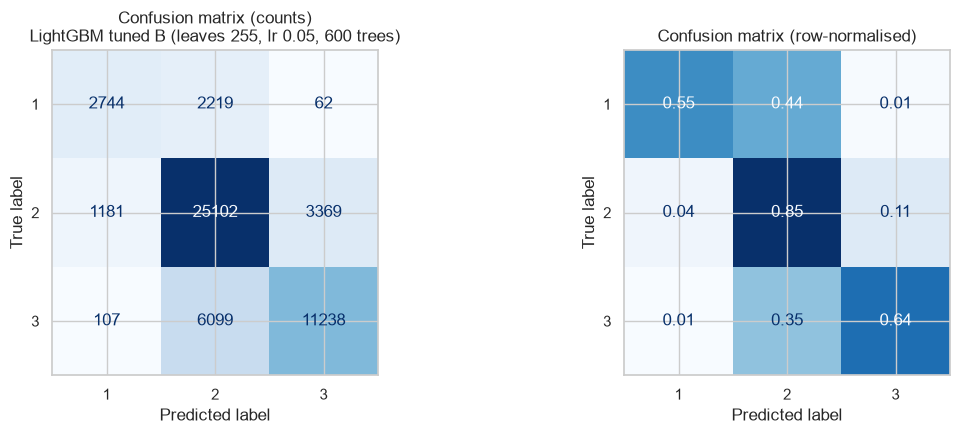

In [17]:
best_model, best_pred = fitted[best_name], preds[best_name]
print(classification_report(y_val + 1, best_pred + 1, target_names=['Grade 1 (low)', 'Grade 2 (medium)', 'Grade 3 (severe)'], digits=3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_val + 1, best_pred + 1, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion matrix (counts)\n{best_name}')
ConfusionMatrixDisplay.from_predictions(y_val + 1, best_pred + 1, normalize='true', ax=axes[1], cmap='Blues', colorbar=False, values_format='.2f')
axes[1].set_title('Confusion matrix (row-normalised)')
plt.tight_layout(); plt.show()

## 2.5 Cross-validation of the best model (stability check)

In [18]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
X_all_t = X.copy()
X_all_t[cat_cols] = OrdinalEncoder().fit_transform(X[cat_cols]).astype(int)
cv_scores = cross_val_score(best_model, X_all_t, y, cv=cv, scoring='f1_micro', n_jobs=1)
print('3-fold micro-F1:', cv_scores.round(4), '| mean = %.4f ± %.4f' % (cv_scores.mean(), cv_scores.std()))

3-fold micro-F1: [0.7442 0.7483 0.7452] | mean = 0.7459 ± 0.0018


## 2.6 Which features drive the predictions?

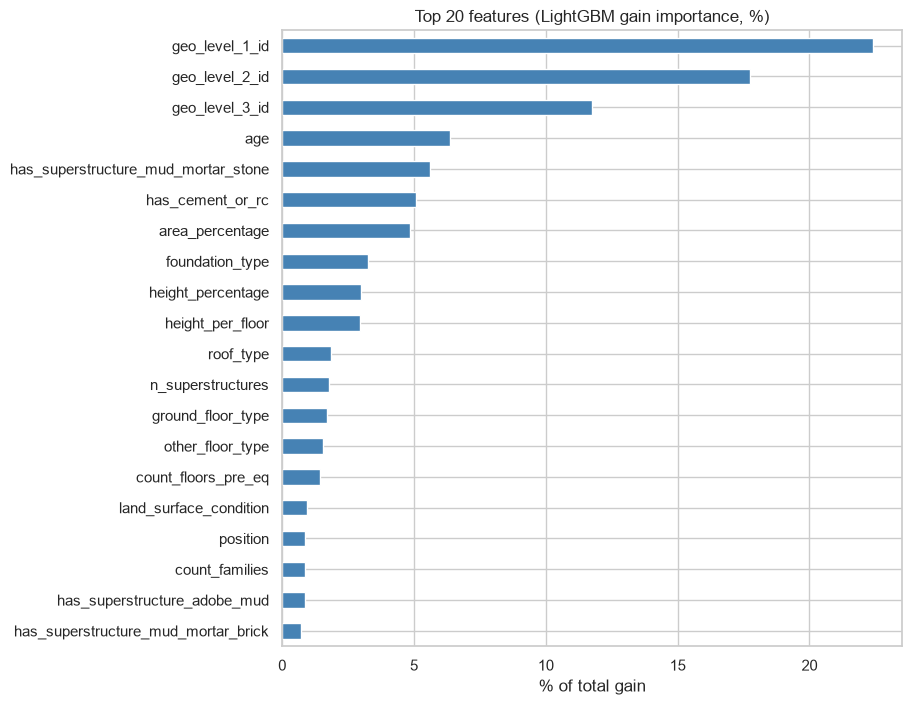

geo_level_1_id                         22.40
geo_level_2_id                         17.73
geo_level_3_id                         11.75
age                                     6.35
has_superstructure_mud_mortar_stone     5.59
has_cement_or_rc                        5.08
area_percentage                         4.85
foundation_type                         3.24
height_percentage                       3.00
height_per_floor                        2.93
roof_type                               1.84
n_superstructures                       1.78
ground_floor_type                       1.71
other_floor_type                        1.54
count_floors_pre_eq                     1.45
dtype: float64

Grouped importance (% of gain):
Geography (geo 1/2/3)                                               51.9
Size & age                                                          18.6
Superstructure materials                                            16.8
Floor/foundation/roof types                               

In [19]:
imp = pd.Series(best_model.booster_.feature_importance(importance_type='gain'), index=X_train_t.columns)
imp = (imp / imp.sum() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 8))
imp.head(20).iloc[::-1].plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Top 20 features (LightGBM gain importance, %)'); ax.set_xlabel('% of total gain')
plt.show()
print(imp.head(15).round(2))

# Grouped importance
groups = {'Geography (geo 1/2/3)': geo_cols,
          'Superstructure materials': sup_cols + ['n_superstructures', 'has_cement_or_rc'],
          'Floor/foundation/roof types': ['foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type'],
          'Size & age': ['count_floors_pre_eq', 'age', 'age_suspect', 'area_percentage', 'height_percentage', 'height_per_floor'],
          'Other (position, plan, ownership, land, families, secondary use)':
              ['position', 'plan_configuration', 'legal_ownership_status', 'land_surface_condition', 'count_families'] + sec_cols}
grp = pd.Series({k: imp[v].sum() for k, v in groups.items()}).sort_values(ascending=False).round(1)
print('\nGrouped importance (% of gain):'); print(grp)

# Task 3 – Suggestions to Seismologists

**Important framing:** earthquakes themselves cannot be prevented, so these suggestions are about *avoiding the significant building damage* that earthquakes cause. They come from patterns in this survey data and the model's feature importance. They are associations from observational data, not proven causes, and the categorical building codes are obfuscated, so the findings point to *which codes* are risky rather than naming real construction types.

**1. Prioritise by location.** Geography is the strongest group of predictors (about 52% of the model's total gain across the three geo levels), and mean damage ranges from about 1.7 to about 2.8 between level-1 regions. Seismologists and planners should build region- and sub-region-level risk maps, and focus inspections, retrofitting funds and monitoring on the consistently high-damage regions (e.g. regions 17 and 18 in this data).

**2. Target mud-mortar and loose-stone buildings for retrofitting.** Mud-mortar-stone (about 76% of the building stock, mean damage 2.34), stone (2.45) and adobe/mud (2.35) are the highest-risk materials. Replacing or strengthening these should be the first priority of any retrofit programme.

**3. Promote cement-bonded and reinforced construction.** Engineered RC (mean damage 1.38), cement-mortar-brick (1.69) and non-engineered RC (1.78) show the lowest damage. Building codes and subsidies should favour cement/concrete-based construction with engineering oversight. The gap between engineered and non-engineered RC also supports requiring inspection and quality control.

**4. Look at foundation, roof and floor systems.** One foundation type (`i`), one roof type (`x`), and particular ground-floor (`v`) and upper-floor (`s`) types are associated with much less damage than the common types. Engineers should identify what these obfuscated codes correspond to in reality and promote those practices.

**5. Watch height, floors and age.** Taller, multi-floor and older buildings tend to be more damaged. Older stock should be screened first for structural assessment.

**6. Use the model as a rapid triage tool.** With about 75% accuracy, the model can rank buildings by likely damage so inspectors visit the highest-risk ones first after an earthquake, or so that pre-event retrofit lists can be prioritised. It should support, not replace, engineering inspection.

**7. Improve data collection.** Capturing real (non-obfuscated) construction types, soil and ground-shaking intensity, distance to the fault, and fixing placeholder `age` values would likely improve both the model and the recommendations. Shaking intensity in particular is not in this dataset, and location is probably acting as a stand-in for it.

# Model Comparison Report

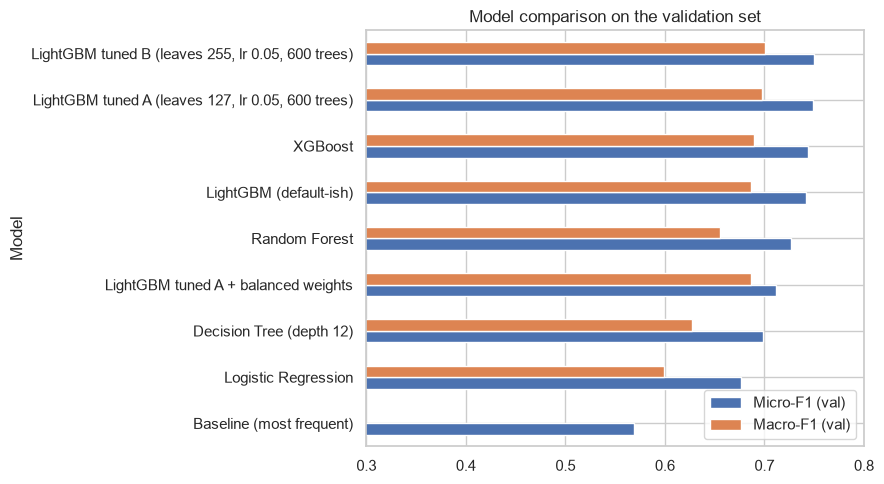

,Model,Micro-F1 (val),Macro-F1 (val),Weighted-F1 (val),Recall G1,Recall G2,Recall G3,Train time (s)
0,"LightGBM tuned B (leaves 255, lr 0.05, 600 trees)",0.7499,0.7006,0.7455,0.546,0.847,0.644,85.8
1,"LightGBM tuned A (leaves 127, lr 0.05, 600 trees)",0.7491,0.6973,0.7436,0.528,0.856,0.630,47.6
2,XGBoost,0.7436,0.6895,0.7376,0.512,0.854,0.622,17.1
3,LightGBM (default-ish),0.7417,0.6863,0.7354,0.505,0.856,0.616,13.6
4,Random Forest,0.7262,0.6553,0.7157,0.430,0.871,0.566,10.6
5,LightGBM tuned A + balanced weights,0.7113,0.6866,0.7157,0.827,0.671,0.747,55.6
6,Decision Tree (depth 12),0.6990,0.6270,0.6900,0.411,0.829,0.561,1.5
7,Logistic Regression,0.6767,0.5990,0.6654,0.370,0.819,0.524,393.0
8,Baseline (most frequent),0.5689,0.2417,0.4126,0.000,1.000,0.000,0.0


In [20]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = res.set_index('Model')[['Micro-F1 (val)', 'Macro-F1 (val)']].sort_values('Micro-F1 (val)')
plot_df.plot(kind='barh', ax=ax)
ax.set_xlim(0.3, 0.8); ax.set_title('Model comparison on the validation set')
plt.tight_layout(); plt.show()
display(res)

## Summary of results (single stratified 80/20 split, 52,121 validation buildings)

| Rank | Model | Micro-F1 | Macro-F1 | Notes |
|---|---|---|---|---|
| 1 | LightGBM tuned B (255 leaves, lr 0.05, 600 trees) | **0.7499** | **0.7006** | best overall, about 65 s to train |
| 2 | LightGBM tuned A (127 leaves) | 0.7491 | 0.6973 | almost identical, faster |
| 3 | XGBoost | 0.7441 | 0.6897 | strong and quick (28 s) |
| 4 | LightGBM (initial settings) | 0.7417 | 0.6863 | before tuning |
| 5 | Random Forest | 0.7262 | 0.6553 | weaker on grade 1 |
| 6 | LightGBM tuned A + balanced class weights | 0.7113 | 0.6866 | much higher minority recall, lower overall score |
| 7 | Decision Tree (depth 12) | 0.6990 | 0.6270 | simple and interpretable |
| 8 | Logistic Regression | 0.6767 | 0.5989 | linear, no geo 2/3 information |
| 9 | Baseline (most frequent class) | 0.5689 | 0.2417 | reference point |

**Findings**
- Gradient-boosted trees beat every other family. Going from the baseline (0.569) to LightGBM (0.750) is a gain of about 18 points of micro-F1.
- The linear model scored lowest of the real models. The signal is non-linear and interaction-heavy (materials, location and building size interact), which fits the weak individual correlations seen in the EDA.
- Tuning LightGBM added about 0.8 points over its initial settings. The two tuned configurations differ by under 0.1 point, so the result is not very sensitive to those parameters.
- 3-fold cross-validation of the best model gave a micro-F1 of 0.7459 ± 0.0018, consistent with the 0.7499 on the validation split, so the model looks stable.
- The best model's recall is 0.55 for grade 1, 0.85 for grade 2 and 0.64 for grade 3. Grade 1 and grade 3 are still often pushed toward grade 2, which is the majority class.
- Balanced class weights raise recall for grade 1 (0.83) and grade 3 (0.75) but reduce grade 2 recall and overall micro-F1 (0.711). It is a trade-off, not a free improvement.

## Recommendation for production
**Use LightGBM (configuration A or B).** Configuration B has the best scores, and A is nearly as accurate with a shorter training time, so either is reasonable. Reasons: highest micro-F1 and macro-F1, stable under cross-validation, fast prediction, native handling of mixed features, and easy feature-importance output.

**Choose the operating point by the use case.** If the goal is the highest overall accuracy (the competition metric), use the unweighted model. If missing severely damaged buildings (grade 3) is the costlier error, as in post-disaster triage, the class-weighted version catches more of them (recall 0.75 vs 0.64), at the price of more false alarms. Probability thresholds could also be tuned for this.

**Caveats before deploying:** results come from one dataset and one earthquake, and the geographic ids make the model specific to these regions. Performance on a different earthquake or on new regions is untested and should be validated before use. The hyperparameter search here was a small manual comparison, not an exhaustive search, so some further gain is probably possible. XGBoost is a good alternative if an existing stack prefers it.

# Report on Challenges Faced

| # | Challenge | What we saw | Technique used | Why |
|---|---|---|---|---|
| 1 | **Class imbalance** | Grade 2 is about 57% of buildings, grade 3 about 33% and grade 1 only about 10% | Reported macro-F1 and per-class recall next to micro-F1, used stratified splits, and tested `class_weight='balanced'` | Accuracy alone hides weak minority performance. Stratification keeps class ratios equal in train and validation. Class weighting raised minority recall but lowered micro-F1, so it is presented as an option. |
| 2 | **Impossible `age` values** | Ages up to 995, with about 1,500 buildings at 200 or more | Capped `age` at 100 and added an `age_suspect` flag | Values like these are likely placeholders. Capping stops them distorting the linear model and the splits, while the flag keeps any information in the fact that they are unusual. Rows were not deleted, since they are only about 0.6% of data and still have valid other features. |
| 3 | **High-cardinality geography** | 31 / 1,414 / 11,595 distinct values at the three geo levels | Kept `geo_level_2/3` as numeric ids for tree models, one-hot encoded only level 1 for the linear model, and dropped level 2/3 there | One-hot encoding thousands of categories would be huge and sparse. Tree models can split on id ranges directly. The ids are not ordered by size, so this works through repeated splitting, and it is a limitation for unseen regions. |
| 4 | **Obfuscated categorical codes** | Letters carry no meaning and the same letter in different columns is unrelated | Ordinal encoding for trees and one-hot for the linear model, with no manual grouping | With no domain meaning there is no safe way to merge or rank categories. Trees are insensitive to the arbitrary ordering, one-hot avoids implying an order for the linear model. |
| 5 | **Weak individual correlations** | No feature has a Spearman correlation above about 0.27 with the target | Moved to non-linear ensemble models and added a few engineered features (`n_superstructures`, `height_per_floor`, `has_cement_or_rc`) | The signal comes from interactions. Boosted trees captured them (0.750 vs 0.677 for logistic regression). |
| 6 | **Choosing and tuning models fairly** | Many model families, with a risk of overfitting the validation set | Same split and preprocessing for all models, a small set of tuned LightGBM settings, and a 3-fold CV check on the final model | Keeps comparisons fair and confirms the gain is not an artefact of one split (CV mean 0.7459 vs 0.7499 on the split). |
| 7 | **Compute limits** | 260k rows, with large ensembles and several configurations | Histogram-based boosting (LightGBM, XGBoost), moderate forest size, and a limited manual tuning search instead of a full grid | Keeps total run time reasonable. A larger search might add a little more accuracy. |
| 8 | **Interpretation limits** | The data is observational and the categories are hidden | Phrased the findings as associations and recommended collecting richer data | Feature importance and group averages do not prove causes, and shaking intensity and soil type are not in the data, so geography may be acting as a stand-in for them. |